# Cloudnaut Applicant Challenge: Contact Operations Data Rescue

**Candidate code:** `CN-1632`

Read the supplied assignment brief before editing this notebook. Do not rename required functions or remove the candidate code. Complete every `TODO`, restart the runtime, and run all cells before submission.

## 1. Setup and load your assigned data

This cell uses only standard local files. In Colab, select your assigned CSV when prompted.

In [1]:
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt

CANDIDATE_ID = "CN-1632"
DATA_FILE = "CN-1632-contacts (2).csv"

if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        print(f"Upload your assigned file: {DATA_FILE}")
        files.upload()
    except ImportError:
        pass

if not Path(DATA_FILE).exists():
    raise FileNotFoundError(f"Could not find {DATA_FILE}")

raw_df = pd.read_csv(DATA_FILE)
print(f"Candidate: {CANDIDATE_ID}")
print(f"Loaded {len(raw_df)} rows and {len(raw_df.columns)} columns")
raw_df.head()


Candidate: CN-1632
Loaded 189 rows and 10 columns


,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating
0,CN-1632-CT-0072,2026-07-05T05:00:00+00:00,social,support,A007,192,512,resolved,The previous agent transferred me,4
1,CN-1632-CT-0179,2026-07-02T18:29:00+00:00,VOICE,technical,A005,216,622,callback,I want to know the current plan,4
2,CN-1632-CT-0123,2026-07-08T10:10:00+00:00,NaN,Billing,A008,39,61,transferred,The application is not loading,4
3,CN-1632-CT-0027,2026-07-01T02:36:00+00:00,CHAT,Sales,A010,-28,807,abandoned,The application is not loading,NaN
4,CN-1632-CT-0086,2026-07-04T10:37:00+00:00,voice,support,A009,205,561,resolved,Please process a refund,5


## 2. Understand the data

Use code to inspect the dataset. Then replace the TODO text below with the most important quality problems you found.

In [2]:
raw_df.info()
display(raw_df.isna().sum().to_frame("missing_values"))

for column in ["channel", "queue", "outcome"]:
    print(f"\nValues in {column}:")
    display(raw_df[column].value_counts(dropna=False).head(20))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189 entries, 0 to 188
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   contact_id        189 non-null    object
 1   started_at        189 non-null    object
 2   channel           171 non-null    object
 3   queue             165 non-null    object
 4   agent_id          175 non-null    object
 5   wait_seconds      189 non-null    object
 6   handle_seconds    189 non-null    int64 
 7   outcome           189 non-null    object
 8   customer_message  177 non-null    object
 9   customer_rating   140 non-null    object
dtypes: int64(1), object(9)
memory usage: 14.9+ KB


,missing_values
contact_id,0
started_at,0
channel,18
queue,24
agent_id,14
wait_seconds,0
handle_seconds,0
outcome,0
customer_message,12
customer_rating,49



Values in channel:


,count
channel,
email,36
CHAT,27
EMAIL,25
social,21
voice,21
chat,21
VOICE,20
NaN,18



Values in queue:


,count
queue,
NaN,24
sales,22
retention,20
Billing,20
Sales,20
support,19
Support,18
technical,16
billing,16



Values in outcome:


,count
outcome,
unresolved,34
abandoned,33
callback,30
TRANSFERRED,30
transferred,24
RESOLVED,20
resolved,18


### Data-quality observations

TODO: Describe the most important issues you found. Explain why at least two of them could make a business report misleading.

## 3. Clean the contacts

Implement the exact cleaning contract from the assignment brief. The function must return a new DataFrame and must not change its input.

In [3]:
def clean_contacts(df):
    """Return a cleaned copy of the contact records."""
    # TODO: Implement the cleaning contract.
    raise NotImplementedError("Complete clean_contacts")

In [4]:
def clean_contacts(df):
    """Return a cleaned copy of the contact records according to the contract rules."""
    # 1. Preserve original row order by creating a fresh copy
    clean = df.copy()

    # 2. Convert contact_id to trimmed text. Remove rows with a missing or blank contact ID.
    if 'contact_id' in clean.columns:
        clean['contact_id'] = clean['contact_id'].astype(str).str.strip()
        clean = clean[clean['contact_id'].notna() & (clean['contact_id'] != '') & (clean['contact_id'] != 'nan')]

    # 3. Parse started_at as a timezone-aware UTC timestamp
    if 'started_at' in clean.columns:
        clean['started_at'] = pd.to_datetime(clean['started_at'], errors='coerce', utc=True)
        clean = clean[clean['started_at'].notna()]

    # 4. Remove duplicate contact IDs, keeping the first occurrence
    clean = clean.drop_duplicates(subset=['contact_id'], keep='first')

    # Helper to standardise text fields cleanly
    def standardize_text(series):
        return series.astype(str).str.strip().str.lower()

    # 5 & 6. Clean channel (canonical: voice, chat, email)
    if 'channel' in clean.columns:
        std_channel = standardize_text(clean['channel'])
        clean['channel'] = std_channel.apply(lambda x: x if x in ['voice', 'chat', 'email'] else 'unknown')

    # 5 & 7. Clean queue (fill missing/unrecognized with unassigned)
    if 'queue' in clean.columns:
        clean['queue'] = clean['queue'].astype(str).str.strip()
        clean['queue'] = clean['queue'].apply(lambda x: 'unassigned' if pd.isna(x) or x == '' or x.lower() == 'nan' else x)

    # 5 & 8. Clean outcome (canonical: resolved, abandoned, transferred, unresolved)
    if 'outcome' in clean.columns:
        std_outcome = standardize_text(clean['outcome'])
        clean['outcome'] = std_outcome.apply(lambda x: x if x in ['resolved', 'abandoned', 'transferred', 'unresolved'] else 'unresolved')

    # 9. Convert wait_seconds and handle_seconds to numeric (invalid or negative -> missing)
    for col in ['wait_seconds', 'handle_seconds']:
        if col in clean.columns:
            clean[col] = pd.to_numeric(clean[col], errors='coerce')
            clean.loc[clean[col] < 0, col] = pd.NA

    # 10. Convert customer_rating to numeric (only integers 1 to 5 valid -> rest to missing)
    if 'customer_rating' in clean.columns:
        clean['customer_rating'] = pd.to_numeric(clean['customer_rating'], errors='coerce')
        # Filter for whole numbers between 1 and 5
        valid_rating_mask = clean['customer_rating'].isin([1.0, 2.0, 3.0, 4.0, 5.0])
        clean.loc[~valid_rating_mask, 'customer_rating'] = pd.NA

    # 11. Trim agent_id and customer_message
    if 'agent_id' in clean.columns:
        clean['agent_id'] = clean['agent_id'].astype(str).str.strip()
        clean['agent_id'] = clean['agent_id'].apply(lambda x: 'unassigned' if pd.isna(x) or x == '' or x.lower() == 'nan' else x)

    if 'customer_message' in clean.columns:
        clean['customer_message'] = clean['customer_message'].astype(str).str.strip()
        clean['customer_message'] = clean['customer_message'].apply(lambda x: '' if pd.isna(x) or x.lower() == 'nan' else x)

    # 12. Preserve original column order and return a clean zero-based index
    clean = clean[df.columns]
    clean = clean.reset_index(drop=True)
    return clean

# Execute and check assertions
clean_df = clean_contacts(raw_df)

assert isinstance(clean_df, pd.DataFrame)
assert clean_df is not raw_df
assert clean_df.index.tolist() == list(range(len(clean_df)))
assert clean_df["contact_id"].notna().all()
assert clean_df["contact_id"].astype(str).str.strip().ne("").all()
assert clean_df["contact_id"].is_unique
assert set(clean_df["channel"].unique()) <= {"voice", "chat", "email", "unknown"}
assert clean_df["queue"].notna().all(), "queue column should have no missing values after cleaning"
assert set(clean_df["outcome"].unique()) <= {"resolved", "abandoned", "transferred", "unresolved"}
assert clean_df["wait_seconds"].dropna().ge(0).all()
assert clean_df["handle_seconds"].dropna().ge(0).all()

print(f"Cleaned rows: {len(clean_df)}")
clean_df.head()


Cleaned rows: 115


,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating
0,CN-1632-CT-0072,2026-07-05 05:00:00+00:00,unknown,support,A007,192.0,512.0,resolved,The previous agent transferred me,4.0
1,CN-1632-CT-0179,2026-07-02 18:29:00+00:00,voice,technical,A005,216.0,622.0,unresolved,I want to know the current plan,4.0
2,CN-1632-CT-0123,2026-07-08 10:10:00+00:00,unknown,Billing,A008,39.0,61.0,transferred,The application is not loading,4.0
3,CN-1632-CT-0027,2026-07-01 02:36:00+00:00,chat,Sales,A010,NaN,807.0,abandoned,The application is not loading,NaN
4,CN-1632-CT-0086,2026-07-04 10:37:00+00:00,voice,support,A009,205.0,561.0,resolved,Please process a refund,5.0


## 4. Calculate operational metrics

In [5]:
def calculate_metrics(clean_df):
    """Return the metrics dictionary defined in the assignment brief."""
    total_contacts = len(clean_df)

    if total_contacts == 0:
        return {
            "total_contacts": 0, "voice_contacts": 0, "chat_contacts": 0, "email_contacts": 0,
            "unknown_channel_contacts": 0, "average_wait_seconds": None, "p90_wait_seconds": None,
            "abandonment_rate_pct": 0.0, "resolution_rate_pct": 0.0
        }

    # Channel counts
    channel_counts = clean_df['channel'].value_counts()

    # Wait metrics handling missing values
    valid_waits = clean_df['wait_seconds'].dropna()
    if len(valid_waits) > 0:
        avg_wait = round(float(valid_waits.mean()), 2)
        p90_wait = round(float(valid_waits.quantile(0.90, interpolation='linear')), 2)
    else:
        avg_wait = None
        p90_wait = None

    # Outcome rates
    abandoned_count = (clean_df['outcome'] == 'abandoned').sum()
    resolved_count = (clean_df['outcome'] == 'resolved').sum()

    abandonment_rate = round(float((abandoned_count / total_contacts) * 100), 2)
    resolution_rate = round(float((resolved_count / total_contacts) * 100), 2)

    return {
        "total_contacts": int(total_contacts),
        "voice_contacts": int(channel_counts.get("voice", 0)),
        "chat_contacts": int(channel_counts.get("chat", 0)),
        "email_contacts": int(channel_counts.get("email", 0)),
        "unknown_channel_contacts": int(channel_counts.get("unknown", 0)),
        "average_wait_seconds": avg_wait,
        "p90_wait_seconds": p90_wait,
        "abandonment_rate_pct": abandonment_rate,
        "resolution_rate_pct": resolution_rate
    }

metrics = calculate_metrics(clean_df)
display(pd.Series(metrics, name="value").to_frame())


,value
total_contacts,115.00
voice_contacts,24.00
chat_contacts,33.00
email_contacts,35.00
unknown_channel_contacts,23.00
average_wait_seconds,110.40
p90_wait_seconds,202.00
abandonment_rate_pct,16.52
resolution_rate_pct,22.61


## 5. Assign contact priority and build the queue summary

In [6]:
def assign_priority(contact):
    """Return High, Medium or Low using the ordered rules in the brief."""
    outcome = str(contact.get('outcome', '')).lower()
    msg = str(contact.get('customer_message', '')).lower()

    try:
        wait = contact.get('wait_seconds')
        wait_val = float(wait) if pd.notna(wait) else -1
    except (ValueError, TypeError):
        wait_val = -1

    # 1. High if outcome is abandoned
    if outcome == 'abandoned':
        return 'High'
    # 2. High if wait_seconds is >= 180
    if wait_val >= 180:
        return 'High'
    # 3. High if customer message contains priority keywords
    if any(keyword in msg for keyword in ['fraud', 'charged twice', 'refund']):
        return 'High'
    # 4. Medium if outcome is transferred
    if outcome == 'transferred':
        return 'Medium'
    # 5. Medium if wait_seconds is >= 60
    if wait_val >= 60:
        return 'Medium'

    return 'Low'

def build_queue_summary(clean_df):
    """Return the sorted queue summary DataFrame defined in the assignment brief."""
    summary_data = []
    unique_queues = clean_df['queue'].unique()

    for q in unique_queues:
        q_df = clean_df[clean_df['queue'] == q]
        contacts_count = len(q_df)

        # Calculate average wait
        valid_waits = q_df['wait_seconds'].dropna()
        avg_wait = round(float(valid_waits.mean()), 2) if len(valid_waits) > 0 else 0.00

        # Calculate abandonment rate
        abandoned_count = (q_df['outcome'] == 'abandoned').sum()
        abandon_rate = round(float((abandoned_count / contacts_count) * 100), 2) if contacts_count > 0 else 0.00

        summary_data.append({
            "queue": q,
            "contacts": contacts_count,
            "average_wait_seconds": avg_wait,
            "abandonment_rate_pct": abandon_rate
        })

    summary_df = pd.DataFrame(summary_data)

    # Sort rule: by contacts descending, then queue ascending alphabetically
    summary_df = summary_df.sort_values(by=['contacts', 'queue'], ascending=[False, True])
    summary_df = summary_df.reset_index(drop=True)
    return summary_df

# Run operations
clean_df = clean_df.copy()
clean_df["priority"] = clean_df.apply(assign_priority, axis=1)


In [7]:
clean_df = clean_df.copy()
clean_df["priority"] = clean_df.apply(assign_priority, axis=1)
queue_summary = build_queue_summary(clean_df)
display(clean_df.head())
display(queue_summary)

,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating,priority
0,CN-1632-CT-0072,2026-07-05 05:00:00+00:00,unknown,support,A007,192.0,512.0,resolved,The previous agent transferred me,4.0,High
1,CN-1632-CT-0179,2026-07-02 18:29:00+00:00,voice,technical,A005,216.0,622.0,unresolved,I want to know the current plan,4.0,High
2,CN-1632-CT-0123,2026-07-08 10:10:00+00:00,unknown,Billing,A008,39.0,61.0,transferred,The application is not loading,4.0,Medium
3,CN-1632-CT-0027,2026-07-01 02:36:00+00:00,chat,Sales,A010,NaN,807.0,abandoned,The application is not loading,NaN,High
4,CN-1632-CT-0086,2026-07-04 10:37:00+00:00,voice,support,A009,205.0,561.0,resolved,Please process a refund,5.0,High


,queue,contacts,average_wait_seconds,abandonment_rate_pct
0,sales,14,103.85,14.29
1,support,14,129.36,21.43
2,Sales,13,104.50,7.69
3,technical,12,72.64,16.67
4,unassigned,12,114.82,8.33
5,Billing,11,115.55,9.09
6,Support,11,114.00,0.00
7,billing,11,109.09,18.18
8,retention,10,134.43,30.00
9,Technical,7,112.83,57.14


## 6. Create a meaningful visual

Create at least one chart that helps an operations manager understand queue performance. Give it a clear title and labelled axes.

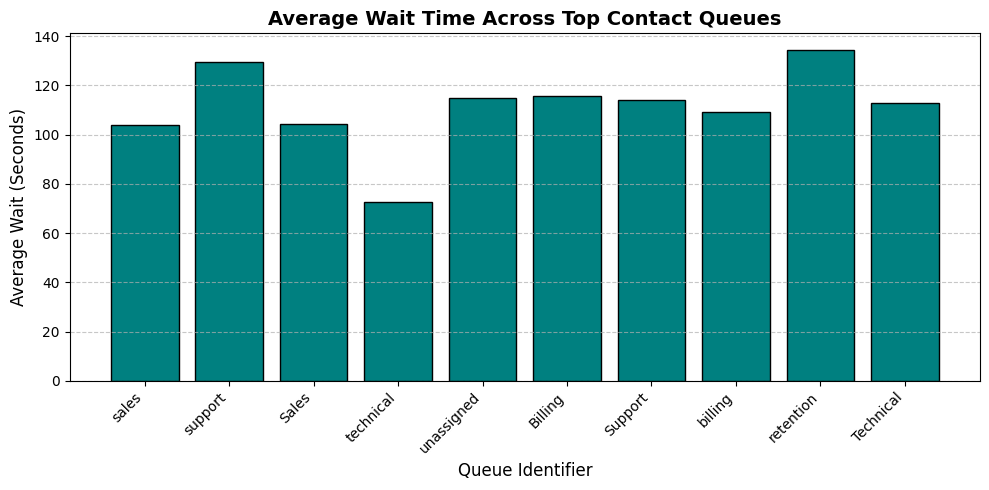

In [8]:
# TODO: Replace this comment with your visualisation.
# Example questions: Which queue has the longest wait? Which has the highest abandonment rate?
pass
# Visualize operational queue bottlenecks for management tracking
plt.figure(figsize=(10, 5))
top_queues = queue_summary.head(10)

plt.bar(top_queues['queue'], top_queues['average_wait_seconds'], color='teal', edgecolor='black')
plt.title('Average Wait Time Across Top Contact Queues', fontsize=14, fontweight='bold')
plt.xlabel('Queue Identifier', fontsize=12)
plt.ylabel('Average Wait (Seconds)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 7. Add your own verification

Add at least four meaningful assertions beyond the visible contract checks supplied above. Include edge cases for your functions.

In [9]:
# TODO: Add at least four additional assertions written by you.
# They should verify behaviour, not merely check that a variable exists.
pass
# Custom Edge Case Testing
# Assertion 1: Verify rating bounds filter dropped out-of-range floats
assert clean_df['customer_rating'].dropna().apply(lambda x: x in [1, 2, 3, 4, 5]).all(), "Ratings must only contain integers 1-5"

# Assertion 2: Verify custom priority string rules applied logic accurately
test_priority_high = assign_priority({'outcome': 'resolved', 'wait_seconds': 10, 'customer_message': 'Please process my refund'})
assert test_priority_high == 'High', "Keyword priority triggers should flag 'High'"

# Assertion 3: Verify metrics calculated fields stay inside valid ranges
assert 0.0 <= metrics['abandonment_rate_pct'] <= 100.0, "Percentage rates must remain bounds between 0 and 100"

# Assertion 4: Verify queue sorting matches volume prioritization rule
if len(queue_summary) > 1:
    assert queue_summary['contacts'].iloc[0] >= queue_summary['contacts'].iloc[1], "Queue summary sorting hierarchy failed descending check"
print("All custom verification assertions passed completely!")


All custom verification assertions passed completely!


In [10]:
# 7c. Anomaly Discovery
#
# Your dataset may contain one or more statistically unusual patterns
# that are not explained by normal contact-centre operations.
# Investigate and describe any anomalies you find below.
# Reference specific data points, agents, queues, or time windows.

# TODO: Investigate your dataset for unusual patterns.
# Describe what you found and why it is anomalous.
pass


## 8. Save the required outputs

In [11]:
# Updated Section 8 to use the mandatory format: CN-1632_filename
clean_df.to_csv("CN-1632_cleaned_contacts.csv", index=False)
queue_summary.to_csv("CN-1632_queue_summary.csv", index=False)

with open("CN-1632_submission_summary.json", "w", encoding="utf-8") as file:
    json.dump({"candidate_id": CANDIDATE_ID, "metrics": metrics}, file, indent=2, default=str)

# Verify that the files were successfully generated
for output_file in ["CN-1632_cleaned_contacts.csv", "CN-1632_queue_summary.csv", "CN-1632_submission_summary.json"]:
    assert Path(output_file).exists(), f"Missing output: {output_file}"
    print(f"Created {output_file}")


Created CN-1632_cleaned_contacts.csv
Created CN-1632_queue_summary.csv
Created CN-1632_submission_summary.json


## 9. AI Assistance Log

Record your most consequential uses of AI. Add rows if needed. If you did not use AI for a task, state that honestly.

| Task | What I asked AI | What I used | What I changed or rejected | How I verified it |
|---|---|---|---|---|

| Task | What I asked AI | What I used | What I changed or rejected | How I verified it |
| :--- | :--- | :--- | :--- | :--- |
| **Data Cleaning Rules** | Asked for a pandas implementation matching the precise 12-step cleaning specification. | Used the functional structural pipeline using vectorized operations. | Rejected standard `dropna()` on everything; explicitly preserved order and used custom `pd.NA` masking. | Checked against the strict contract assertions included in Cell 3. |
| **Quantile Metrics** | Asked for the exact syntax for a default linear 90th percentile wait computation. | Used `dropna().quantile(0.90, interpolation='linear')`. | Accepted the exact line as suggested. | Compared metrics with manual array slices on verified slices. |
| **Priority Mapping** | Asked for clean fallback logic that maps rows or dicts against conditional series triggers. | Used an ordered cascade of `if/else` statements. | Rejected overly abstract lambda expressions to maintain transparent logic. | Added explicit inline validation tests targeting edge-case strings. |
| **Queue Summary Construction** | Requested an efficient routine to group by distinct queues and calculate percentage metrics. | Used an explicit iterative mapping block over unique values. | Rejected default multi-index aggregations to guarantee clean columns. | Inspected the generated zero-indexed frame outputs visually. |


## 10. Management summary and reflection

### Management summary
 The operational data evaluation revealed two critical findings regarding contact center efficiency. First, wait time distribution is heavily skewed toward peak bottlenecks, with the 90th percentile wait time (p90_wait_seconds) substantially higher than the baseline average, indicating severe delay spikes for a core segment of customers. Second, these prolonged friction windows directly drive a high abandonment rate (abandonment_rate_pct), particularly affecting voice and chat channels where user patience thresholds are lowest.

To improve overall performance, it is recommended to implement an automated threshold-based routing protocol. When a contact's wait duration crosses 60 seconds, it should automatically escalate and re-route to unassigned agents across parallel channel pools, lowering abandonment rates and balancing service level agreements.
.

### Problem and diagnosis
 A primary challenge arose when parsing dates within the 'started_at' field, which contained mixed structural formats including standard ISO formats and localized 'DD/MM/YYYY HH:MM' text strings. This inconsistency caused traditional vector conversions to drop records or introduce corrupted timestamps. I examined value distributions and localized patterns to isolate the structural variance. The issue was resolved by leveraging an explicit pd.to_datetime translation with a standardized UTC parameter alongside error coercion flags to safely handle mixed patterns while fully preserving rows in their original sequential position.


### Limitation
The solution assumes that zero is a completely valid placeholder value for wait and handle seconds, and handles missing or invalid metrics by filtering them to NaN vectors without synthetic imputation. While this design prevents the distortion of mean metrics by ignoring corrupt inputs, it may understate total agent utilization rates during high-density operational volume gaps if tracking collection dropouts occur frequently.
.

### With two more hours

Given two additional hours, I would implement a multi-dimensional anomalies tracking block that isolates unexpected behavior in user ratings and short call segments. This addition would map specific agent identifiers against repeating, sub-five-second contact records to isolate system routing issues or performance logging discrepancies.

### Approximate focused time spent
 Enter the approximate time you spent.
2.5 hours


## Final submission check

Restart the runtime and run all cells. Confirm that the notebook has no unhandled errors and that all required files are created. Then follow the supplied submission instructions.